# 跨溶剂化学位移迁移

从源溶剂下的实测位移估计目标溶剂中的谱。

实验参考模型检索具有两种溶剂配对测量的相似分子环境，把参考中的溶剂位移差加到查询位移上，同时返回参考分子和原子编号。

本教程读取保存的预测，解释输入输出字段，并评估结果。最后给出在新数据集上运行模型的命令。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('nmr.solvent_transfer')
print('Task:', evidence['task'])
print('Examples:', len(evidence['examples']))

Task: nmr.solvent_transfer
Examples: 3


## 输入与输出

| Field | Meaning |
| --- | --- |
| `structure / nucleus` | 分子连接结构及 1H 或 13C 核种。 |
| `solvents` | 显式指定源溶剂与目标溶剂，且参考库包含对应配对。 |
| `source_ppm` | 源溶剂下的实测位移（ppm）。 |

| Field | Meaning |
| --- | --- |
| `target_ppm / delta_ppm` | 从独立参考记录估计目标位移及跨溶剂差值。 |
| `reference` | 参考分子、谱图/原子 ID、Tanimoto 相似度及排除规则。 |

查看下面的示例记录。长数组显示长度与前几个数值，下载 JSON 可获取完整数组。

In [2]:
for example in evidence['examples'][:3]:
    print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "input": {
    "nucleus": "1H",
    "source_ppm": 1.45,
    "source_solvent": "CD3OD",
    "target_solvent": "acetone-d6",
    "query_connectivity": "C1CCCCC1"
  },
  "output": {
    "source_ppm": 1.45,
    "predicted_target_ppm": 1.3799999999999997,
    "predicted_delta_ppm": -0.07000000000000028,
    "source_solvent": "CD3OD",
    "target_solvent": "acetone-d6",
    "nucleus": "1H",
    "query_connectivity": "C1CCCCC1",
    "reference": {
      "identity": "C1COCCO1",
      "molecule_id": "10016061",
      "atom_id": "10093018",
      "source_ppm": 3.66,
      "target_ppm": 3.59,
      "source_spectrum_ids": [
        "20197666"
      ],
      "target_spectrum_ids": [
        "20197080"
      ]
    },
    "tanimoto_similarity": 0.125,
    "same_connectivity_excluded": true,
    "method": "nearest_paired_experimental_reference_delta",
    "model_kind": "retrieval_baseline_not_neural_model",
    "query_molecule_id": "10811",
    "query_atom_id": "10046537",
    "target_reference_pp

## 评估预测

分别使用 ppm 单位的 MAE 评估 H 与 C 位移。

表格给出每次运行的数据集与指标。后续代码从绘图使用的预测值重新计算汇总结果。

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded evaluation | 13C | atoms | 140 |
| recorded evaluation | 13C | molecules | 13 |
| recorded evaluation | 13C | mae_ppm | 1.09429 |
| recorded evaluation | 13C | unchanged_shift_mae_ppm | 1.16371 |
| recorded evaluation | 13C | rmse_ppm | 1.90935 |
| recorded evaluation | 1H | atoms | 156 |
| recorded evaluation | 1H | molecules | 19 |
| recorded evaluation | 1H | mae_ppm | 0.137628 |
| recorded evaluation | 1H | unchanged_shift_mae_ppm | 0.135385 |
| recorded evaluation | 1H | rmse_ppm | 0.376179 |


{
  "scope": "Saved model outputs are shown directly; aggregate metrics are in the run table.",
  "recorded_runs": 1,
  "real_examples": 3
}


## 查看结果图

溶剂间的化学位移迁移。

比较预测与参考，查看返回的结构或峰位置。图由上方读取的记录直接生成。

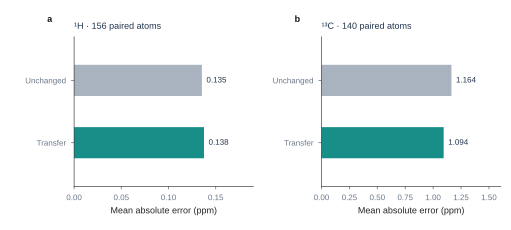

In [4]:
import matplotlib.pyplot as plt
for example_index in range(1):
    figure = render('nmr.solvent_transfer', evidence, example_index=example_index)
    image = io.StringIO()
    figure.savefig(image, format='svg', metadata={'Date': None})
    display(SVG(image.getvalue()))
    plt.close(figure)

## 运行模型

按任务指南配置环境和权重，在 benchmark runner 中选择本任务，即可评估自己的数据集。

```bash
python -m openmolspec_bench run --workspace /path/to/OpenMolSpec \
  --tasks nmr.solvent_transfer --limit 8 --output results/nmr-solvent_transfer.json
```

[Task](../tasks/nmr-solvent_transfer.md) · [Quick start](../quickstart.md)



## 参考文献

- Steinbeck, C., Krause, S. & Kuhn, S. NMRShiftDB—Constructing a Free Chemical Information System with Open-Source Components. Journal of Chemical Information and Computer Sciences 43, 1733–1739 (2003). doi:10.1021/ci0341363. [Source](https://doi.org/10.1021/ci0341363)
